# Week 1 Assignment: Iris classification with Keras

The goal of this project is to build a fully connected neural network (one hidden layer, 3-unit softmax output) that predicts the iris species from four numerical features, and to follow how training progresses.

In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Input
from keras.optimizers import Adam
from keras.utils import to_categorical
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [102]:
random_num = 22

# Seeds for reproducibility
np.random.seed(random_num)
tf.random.set_seed(random_num)

## Data understanding

The dataset is loaded from UCI Machine Learning Repository. It has in total 150 samples, 4 numerical features (sepal length/width, petal length/width) and a species label with three classes.

In [103]:
dataset = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

In [104]:
column_names = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]

Transform the dataset into DataFrame and set the column names

In [105]:
df = pd.read_csv(dataset, names=column_names)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## Data preparation

The data is shuffled due to it being ordered by species and also since `validation_split` only takes the last part of the data as the validation set.

In [106]:
df = df.sample(frac=1, random_state=random_num).reset_index(drop=True)

Input and target features are separated into X and y.

In [107]:
X = df.drop(columns=['species'])
X.head(3)

,sepal_length,sepal_width,petal_length,petal_width
0,5.4,3.7,1.5,0.2
1,6.4,3.2,5.3,2.3
2,6.5,2.8,4.6,1.5


In [108]:
y_raw = df['species']
y_raw.head(3)

0        Iris-setosa
1     Iris-virginica
2    Iris-versicolor
Name: species, dtype: str

The species labels `(y)` are converted to integers and then one-hot encoded.

Lastly, the input features are standardized to zero mean and unit variance, which helps training.

In [109]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

y = to_categorical(y, num_classes=3)

Standardize the input features

In [110]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [111]:
print("\nFeatures shape:", X_scaled.shape)
print("Labels shape:", y.shape)


Features shape: (150, 4)
Labels shape: (150, 3)


## Model

A fully connected network with one hidden layer of 8 ReLU units and an output layer of 3 units with softmax activation. It is trained with categorical cross-entropy loss and accuracy as the metric.

In [112]:
model = Sequential([
    Input(shape=(4,)),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

In [113]:
model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

## Model training with validation split

20% of the data is used for validation through the parameter `validation_split`. No separate test set is used because the dataset is small.

In [114]:
history = model.fit(
    X_scaled,
    y,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.1750 - loss: 1.2531 - val_accuracy: 0.3333 - val_loss: 1.2206
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2667 - loss: 1.1977 - val_accuracy: 0.3333 - val_loss: 1.1753
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3083 - loss: 1.1572 - val_accuracy: 0.3667 - val_loss: 1.1364
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3750 - loss: 1.1212 - val_accuracy: 0.4333 - val_loss: 1.1007
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4167 - loss: 1.0877 - val_accuracy: 0.4333 - val_loss: 1.0675
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4750 - loss: 1.0559 - val_accuracy: 0.4333 - val_loss: 1.0358
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4917 - loss: 1.0254 - val_accuracy: 0.4333 - val_loss: 1.0050
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5083 - loss: 0.9960 - val_accuracy: 0.4667 - val_loss:

## Evaluation and Visualization


Final Training Accuracy:   95.83%
Final Validation Accuracy: 96.67%
Final Training Loss:       0.1967
Final Validation Loss:     0.2318


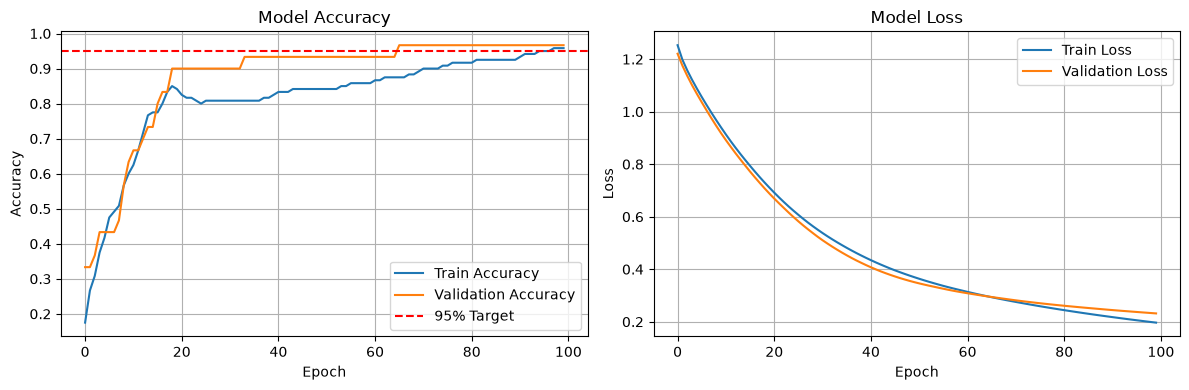

In [115]:
train_acc = history.history['accuracy'][-1]
val_acc = history.history['val_accuracy'][-1]
train_loss = history.history['loss'][-1]
val_loss = history.history['val_loss'][-1]

print(f"\nFinal Training Accuracy:   {train_acc * 100:.2f}%")
print(f"Final Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Final Training Loss:       {train_loss:.4f}")
print(f"Final Validation Loss:     {val_loss:.4f}")

# Plot training & validation accuracy and loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy plot
ax1.plot(history.history['accuracy'], label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax1.axhline(y=0.95, color='r', linestyle='--', label='95% Target')
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss plot
ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Validation Loss')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

- **Loss:** Training loss decreased from `~1.25` to `~0.20`, and validation loss from `~1.22` to `~0.23` over 100 epochs. Both curves decreased steadily and stayed close to each other, with no sign of validation loss rising at the end.
- **Accuracy:** Training accuracy and Validation accuracy both exceeded the required ~95%.
    - Final Training Accuracy:   95.83%
    - Final Validation Accuracy: 96.67%
- **Overfitting:** Training and validation accuracy are close to each other, and the final validation loss (0.23) is only slightly above the training loss (0.20). No clear sign of overfitting.
- **Note:** validation set has only 30 samples, so each mistake changes accuracy by 3.3 percentage points, which makes the validation curve jumpy.
- **Conclusion:** The model learned the task very well with the `rmsprop` setting on `model.compile`. The result reached the target (95%).

## AI assistance

Claude.AI was used during this assignment to check the notebook, help fix errors (e.g. cell types and imports), and give feedback on the structure of the documentation.